In [1]:
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc4
import glob
import datetime as dt
import pickle as pkl
from matplotlib.ticker import ScalarFormatter
#from plot_ACCLIP_profs import plot_model_overlay, get_ACCLIP_merge_data, get_model_prof_data
import os
import jdcal
import plotter_config as pc

In [2]:
def get_model_prof_data(CESMSAVEDIR, vars, ztype, sim, lon_bnds, lat_bnds, quants, jd_range, daterngstr):

    simfile_z = CESMSAVEDIR + vars[0] + ztype + 'profiles_' + sim + '_' + str(lon_bnds) + '_' + str(lat_bnds) + '.pkl'   # '_' + daterngstr
    with open(simfile_z, 'rb') as f:
        var_profs_z, lev_z, jds = pkl.load(f) 
        var_profs_z[var_profs_z > 0] = var_profs_z[var_profs_z > 0]*pc.var_info[vars[0]]['mod']

    if len(vars) > 1: 
        for v in range(len(vars)-1):
            simfile_z = CESMSAVEDIR + vars[v+1] + ztype + 'profiles_' + sim + '_' + str(lon_bnds) + '_' + str(lat_bnds) + '.pkl' # '_' + daterngstr + 
            with open(simfile_z, 'rb') as f:
                curr_var_profs_z, lev_z, jds = pkl.load(f) 
                curr_var_profs_z[curr_var_profs_z > 0] = curr_var_profs_z[curr_var_profs_z > 0]*pc.var_info[vars[v+1]]['mod']
            var_profs_z = var_profs_z + curr_var_profs_z
        
    #var_profs_z = np.append(var_zprofs_in, var_zprofs_out, axis=0)
            
    var_mean = []
    var_lowq = []
    var_upq  = []

    print(np.shape(var_profs_z))
    
    for z in range(len(lev_z)):
        curr_var_z = np.array(var_profs_z[:,z])
        curr_jds = np.asarray(jds)[curr_var_z > 0]        
        curr_var_z = curr_var_z[curr_var_z > 0]  # Correct for the fact that some points may have been flagged as under the surface

        curr_var_z = curr_var_z[(curr_jds >= jd_range[0]) & (curr_jds <= jd_range[1])]

        if len(curr_var_z) > 1:
            var_mean.append(np.mean(curr_var_z))
            var_lowq.append(np.percentile(curr_var_z, quants[0]))
            var_upq.append(np.percentile(curr_var_z, quants[1]))
        else: 
            var_mean.append(-999)
            var_lowq.append(-999)
            var_upq.append(-999)
        
    return lev_z, np.asarray(var_mean), np.asarray(var_lowq), np.asarray(var_upq)

In [3]:
def get_ACCLIP_merge_data(OBSROOT, FLT_DATES, var_str):
    
    OBSvar = []

    if var_str != '':
        for FLT_DATE in FLT_DATES:
        
            AIRFILE = glob.glob(OBSROOT + '*' + FLT_DATE + '*.ict')[0]     
            AIRheaders = np.loadtxt(AIRFILE, delimiter=',', usecols = (0), dtype='str')
            AIRdata = np.loadtxt(AIRFILE, delimiter=',', skiprows=int(AIRheaders[0]))  # Read the file
            OBSvar.extend(AIRdata[:,int(list(AIRheaders).index(var_str))-11])
        
    return np.asarray(OBSvar)

In [4]:
def plot_obs_model_compare(ax, var_data, alt_data, CESMSAVEDIR, sims, var_strs, ztype, lon_bnds, lat_bnds, quants, cols, labs, xlim, daterngstr, jd_range = [0,1e20], log=False):

    #var_mod = pc.var_info[var_str]['mod']
    var_lab = pc.var_info[var_strs[0]]['lab']
    unit = pc.var_info[var_strs[0]]['unit']
    
    ax.scatter(var_data, alt_data, color='k', s=5, zorder=1)
    
    for s in range(len(sims)):

        lev_z, model_mean, model_lowq, model_upq = get_model_prof_data(CESMSAVEDIR, var_strs, ztype, sims[s], lon_bnds, lat_bnds, quants, jd_range, daterngstr)
        ax.fill_betweenx(lev_z, model_lowq, model_upq, color=cols[s], alpha=0.3, zorder=3)          
        ax.plot(model_mean, lev_z, color=cols[s], linewidth = 2, label=labs[s], zorder=5)    # 'MAM4 - CAMS SO2'    

        #for z in range(len(lev_z)):
        #    print(lev_z[z], model_mean[z])

    ax.set_xlim(xlim)
    #ax.set_xlim(left=0)
    if log == True: ax.set_xscale('log')
    ax.set_ylim([1,20])

    ax.set_xlabel(var_lab + ' (' + unit + ')', fontsize=14, fontweight='bold')
    if ztype == 'z': ax.set_ylabel('Altitude (km)', fontsize=14, fontweight='bold')

    ax.legend(fontsize=14)
    

In [5]:

aer_conv = 1013.*100.*1e9/(273.*286.9969)

lon_bndss = [[125,140]]   
lat_bndss = [[25,38]] 

#lon_bndss = [[0,360]]
#lat_bndss = [[-20,20]]

#lon_bndss = [[123,126]]
#lat_bndss = [[33,38]]

vars = ['SO2']


In [6]:

# Define the relevant paths
GV_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_60SEC_Merge/'
WB_OBSROOT = '/glade/work/wsmith/ACCLIP_WB57_R1_60SEC_Merge/'
#ERICA_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_ERICA_Merge/'
#PLOTDIR = '/glade/derecho/scratch/wsmith/carma_plots/'
CESMSAVEDIR = '/glade/u/home/wsmith/ASM_Plotter/vars/'

GV_FLT_DATES = ['20220730','20220804','20220806','20220807','20220812','20220815','20220816','20220819','20220822','20220823','20220825','20220826','20220829','20220830']
#ERICA_FLT_DATES = ['20220804','20220806','20220807','20220812','20220815','20220816','20220819','20220822','20220823','20220825','20220826']
WB_FLT_DATES = ['20220802','20220804','20220806','20220812','20220813','20220815','20220816','20220819','20220821','20220823','20220825','20220826','20220829','20220831','20220901']

#GV_FLT_DATES = ['20220819']
#WB_FLT_DATES = ['20220819']

Aug19_jd_range = [2459810.625,2459810.75]  # 3-6Z on August 19, 2022
jd_range_2022 = [0,2459945.5]


(248, 51)
(248, 51)
(248, 51)


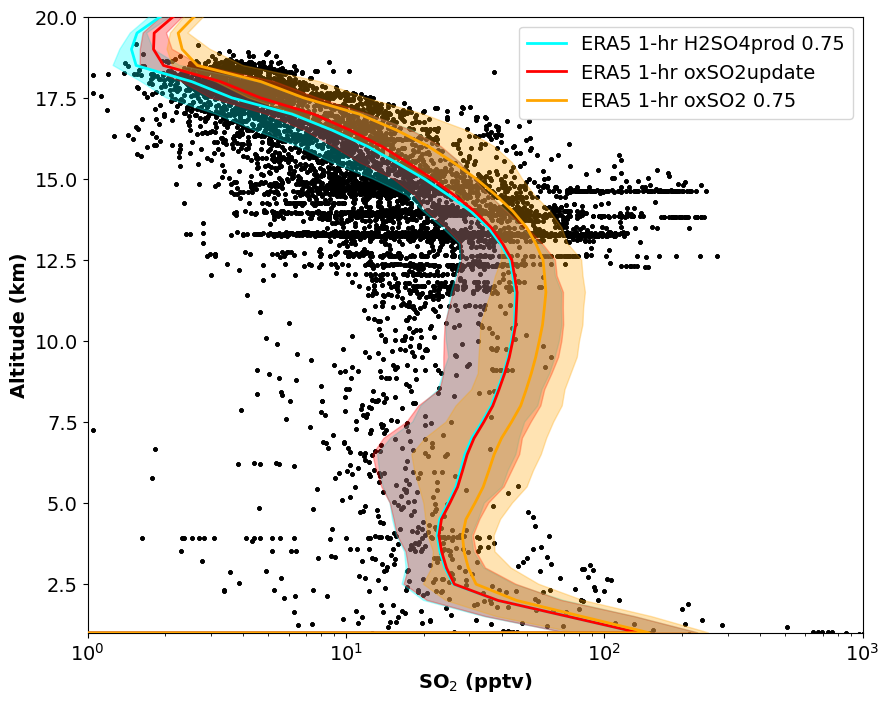

In [7]:

for ltln in range(len(lon_bndss)):
    
    lon_bnds = lon_bndss[ltln]
    lat_bnds = lat_bndss[ltln]
    
    #ACCLIP_GV_ERICA_z = get_ACCLIP_merge_data(ERICA_OBSROOT, ERICA_FLT_DATES, 'GGALT')*1.e-3 
    ACCLIP_GV_z  = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGALT')*1.e-3
    ACCLIP_WB_z  = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_ALT_MMS')*1.e-3

    ACCLIP_GV_var = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, pc.var_info[vars[0]]['GV_inst']) 
    ACCLIP_WB_var = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, pc.var_info[vars[0]]['WB57_inst'])

    if len(ACCLIP_WB_var) < 1: 
        ACCLIP_z = ACCLIP_GV_z
        ACCLIP_var = ACCLIP_GV_var
    else: 
        ACCLIP_z = np.asarray(list(ACCLIP_GV_z) + list(ACCLIP_WB_z))
        ACCLIP_var = np.asarray(list(ACCLIP_GV_var) + list(ACCLIP_WB_var))            
    
    fig = plt.figure(figsize=(10,8))

    if vars[0][0] == 'S' or vars[0][0] == 's': log = True
    else: log = False
    
    ax1  = plt.subplot(1,1,1)    
    #ax2  = plt.subplot(2,2,2) 
    #ax3  = plt.subplot(2,2,3) 
    #ax4  = plt.subplot(2,2,4) 

    # This is for the May 2026 reruns
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_M2-3hr'], vars, 'z', lon_bnds, lat_bnds, [5,95], ['blue'], ['MERRA-2 3-hr'], pc.var_info[vars[0]]['xlim'], '', jd_range = jd_range_2022, log=log)
    plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_E5-1hr_H2SO4prod-0.75'], vars, 'z', lon_bnds, lat_bnds, [5,95], ['cyan'], ['ERA5 1-hr H2SO4prod 0.75'], pc.var_info[vars[0]]['xlim'], '', jd_range = jd_range_2022, log=log)
    plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug2022_E5-1hr_oxSO2update'], vars, 'z', lon_bnds, lat_bnds, [5,95], ['red'], ['ERA5 1-hr oxSO2update'], pc.var_info[vars[0]]['xlim'], '', jd_range = jd_range_2022, log=log)   
    plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug2022_E5-1hr_oxSO2-0.75'], vars, 'z', lon_bnds, lat_bnds, [5,95], ['orange'], ['ERA5 1-hr oxSO2 0.75'], pc.var_info[vars[0]]['xlim'], '', jd_range = jd_range_2022, log=log)    
    
    # This is for the 70L WACCM used as initial conditions
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug19_WACCM'], [var], 'z', lon_bnds, lat_bnds, [5,95], ['red'], ['WACCM_70L'], [0,350], '2022-08-19-2022-08-19')
    
    # These are for previous simulations that were branched on August 10
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug19_ERA5_0.25nudge'], var, 'z', lon_bnds, lat_bnds, [5,95], ['gray'], ['ERA5_0.25nudge_Aug10-20'], [0,350])        
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug19_ERA5_0.25nudge'], var, 'z', lon_bnds, lat_bnds, [5,95], ['red'], ['Nudging toward ERA5 every 1hr'], pc.var_info[var]['xlim'], jd_range = Aug19_jd_range, log=log)
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug19_ERA5_0.25nudge_3hr'], var, 'z', lon_bnds, lat_bnds, [5,95], ['orange'], ['Nudging toward ERA5 every 3hrs'], pc.var_info[var]['xlim'], jd_range = Aug19_jd_range, log=log)
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug19_ERA5_0.25nudge_noZMKE'], var, 'z', lon_bnds, lat_bnds, [5,95], ['orange'], ['ERA5_0.25nudge_Aug19_3-6Z_withoutZM-KE'], [0,350], jd_range = Aug19_jd_range)
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['Aug19_MERRA2_0.25nudge'], var, 'z', lon_bnds, lat_bnds, [5,95], ['blue'], ['Nudging toward MERRA-2 every 3hrs'], pc.var_info[var]['xlim'], jd_range = Aug19_jd_range, log=log)

    # These are for the full campaign (which drastically suppresses the model differences)
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_ERA5_ZM'], var, 'z', lon_bnds, lat_bnds, [5,95], ['cyan'], ['ERA5_ZM_Aug2022'], [0,350]) 
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_ERA5_ZMKE'], var, 'z', lon_bnds, lat_bnds, [5,95], ['blue'], ['ERA5_ZM-KE_Aug2022'], [0,350]) 
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_MERRA2_ZM'], var, 'z', lon_bnds, lat_bnds, [5,95], ['orange'], ['MERRA-2_ZM_Aug2022'], [0,350]) 
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_MERRA2_ZMKE'], var, 'z', lon_bnds, lat_bnds, [5,95], ['red'], ['MERRA-2_ZM-KE_Aug2022'], [0,350]) 

    # These are for the simulations branched on January 1 2022
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_MERRA2_ZM'], var_strs, 'z', lon_bnds, lat_bnds, [5,95], ['blue'], ['MERRA-2_ZM'], pc.var_info[var]['xlim'], '2022-08-01-2022-08-31', jd_range = Aug19_jd_range, log=log) 
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_MERRA2_ZMKE'], var_strs, 'z', lon_bnds, lat_bnds, [5,95], ['cyan'], ['MERRA-2_ZM-KE'], pc.var_info[var]['xlim'], '2022-08-01-2022-08-31', jd_range = Aug19_jd_range, log=log)         
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_ERA5_ZM'], var_strs, 'z', lon_bnds, lat_bnds, [5,95], ['red'], ['ERA5_ZM'], pc.var_info[var]['xlim'], '2022-08-01-2022-08-31', jd_range = Aug19_jd_range, log=log) 
    #plot_obs_model_compare(ax1, ACCLIP_var, ACCLIP_z, CESMSAVEDIR, ['2022_ERA5_ZMKE'], var_strs, 'z', lon_bnds, lat_bnds, [5,95], ['orange'], ['ERA5_ZM-KE'], pc.var_info[var]['xlim'], '2022-08-01-2022-08-31', jd_range = Aug19_jd_range, log=log) 
    
    for label in ax1.get_xticklabels():
        label.set_fontsize(14)
        label.set_fontweight('medium')
    for label in ax1.get_yticklabels():
        label.set_fontsize(14)
        label.set_fontweight('medium')            
    
    #plt.savefig(PLOTDIR + 'SO2_Figure_' + str(lon_bnds) + '_' + str(lat_bnds) + '.png', dpi=300)
    #plt.close('all')



TypeError: get_model_prof_data() takes 9 positional arguments but 10 were given

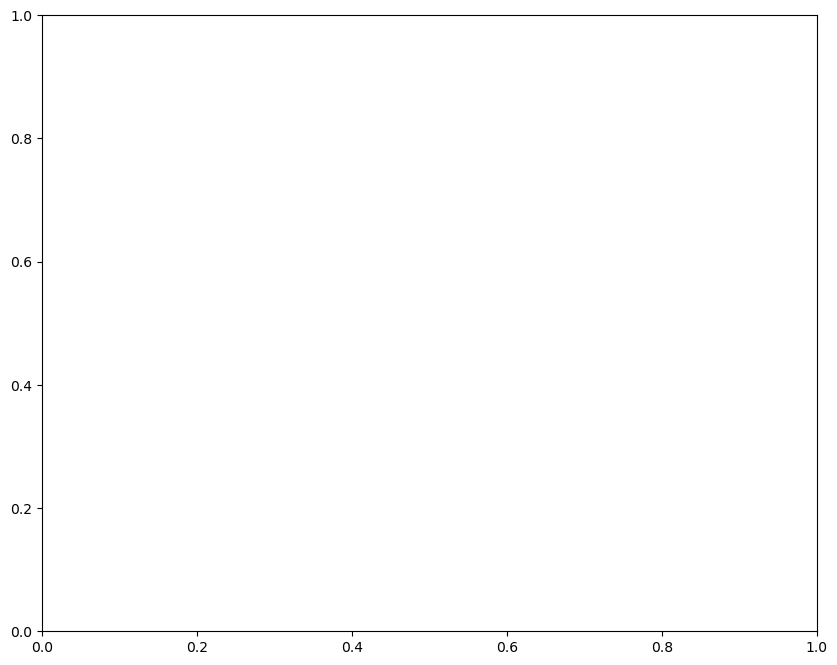

In [8]:

fig = plt.figure(figsize=(10,8))

ax  = plt.subplot(1,1,1) 

lev_z, model_mean, model_lowq, model_upq = get_model_prof_data(CESMSAVEDIR, ['ZMMU'], 'z', '2022_ERA5_ZM', lon_bndss[0], lat_bndss[0], [5,95], 3600., jd_range_2022, '2022-01-01-2022-01-04')
ax.fill_betweenx(lev_z, model_lowq, model_upq, color='red', alpha=0.3, zorder=3)          
ax.plot(model_mean, lev_z, color='red', linewidth = 2, label='2022_ERA5_ZM', zorder=5)    # 'MAM4 - CAMS SO2' 
ax.set_xlim(0,500)
